In [6]:
import pandas as pd

In [7]:
df = pd.read_csv('dane/clastry_all.csv')

In [8]:
df.columns

Index(['h3', 'population', 'population_2021', 'population_kontur',
       'gestosc_os_km2', 'pow_km2', 'dzielnica', 'lon', 'lat', 'poi_biznes',
       ...
       'nowy_przystanek_ocena', 'nowy_przystanek_odl_ztm_m',
       'linie_ztm_do_dolozenia_przystanku', 'wsiadajacy_h_2025',
       'wsiadajacy_h_2036', 'slupki_ztm', 'linie_ztm_na_przystankach',
       'stacje_metro_liczba', 'stacje_kolej_liczba',
       'linie_kolej_metro_liczba'],
      dtype='str', length=163)

In [9]:
df['pred_wykluczenie'].head(5)

0    0.3545
1    0.8708
2    0.7655
3    0.9166
4    0.2942
Name: pred_wykluczenie, dtype: float64

In [14]:
do_usuniecia = ['rank_wykluczenie', 'top30', 'slupki_ztm', 'top30_etykieta']

In [15]:
df = df[[col for col in df.columns if col not in do_usuniecia]]

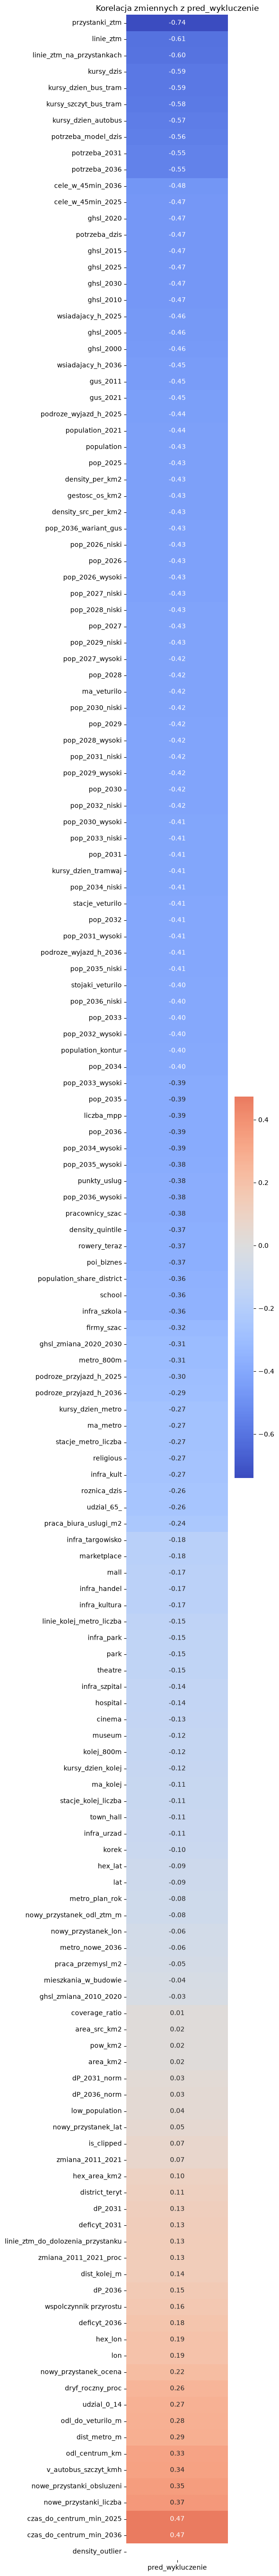

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

cel = 'pred_wykluczenie'  # np. 'pred wykluczenie', jeśli tak nazywa się kolumna
dane_numeryczne = df.select_dtypes(include='number')

korelacje = (
    dane_numeryczne.corr()[[cel]]
    .drop(index=cel)  # usuwa korelację zmiennej z samą sobą
    .sort_values(by=cel)
)

plt.figure(figsize=(6, max(5, len(korelacje) * 0.35)))
sns.heatmap(korelacje, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title(f'Korelacja zmiennych z {cel}')
plt.tight_layout()
plt.show()